In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import accuracy_score

df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data', names=['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'accep'])
df['accep'] = ~(df['accep']=='unacc') #1 is acceptable, 0 if not acceptable

df

,buying,maint,doors,persons,lug_boot,safety,accep
0,vhigh,vhigh,2,2,small,low,False
1,vhigh,vhigh,2,2,small,med,False
2,vhigh,vhigh,2,2,small,high,False
3,vhigh,vhigh,2,2,med,low,False
4,vhigh,vhigh,2,2,med,med,False
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,True
1724,low,low,5more,more,med,high,True
1725,low,low,5more,more,big,low,False
1726,low,low,5more,more,big,med,True


In [11]:
X = pd.get_dummies(df.iloc[:,0:6])
y = df['accep']
x_train, x_test, y_train, y_test = train_test_split(X,y, random_state=0, test_size=0.2)

## decision tree and parameters
dtree = DecisionTreeClassifier()
print(f'Decision Tree parameters: {dtree.get_params()}')

## Fitting decision tree on training set and the depth of the tree
dtree.fit(x_train, y_train)
print(f'Decision tree depth: {dtree.get_depth()}')

## Predicting on test data and accuracy of model on test set
y_pred = dtree.predict(x_test)

print(f'Test set accuracy: {dtree.score(x_test, y_test)}') # or accuracy_score(y_test, y_pred)

Decision Tree parameters: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}
Decision tree depth: 11
Test set accuracy: 0.9826589595375722


## visualizing decision tree

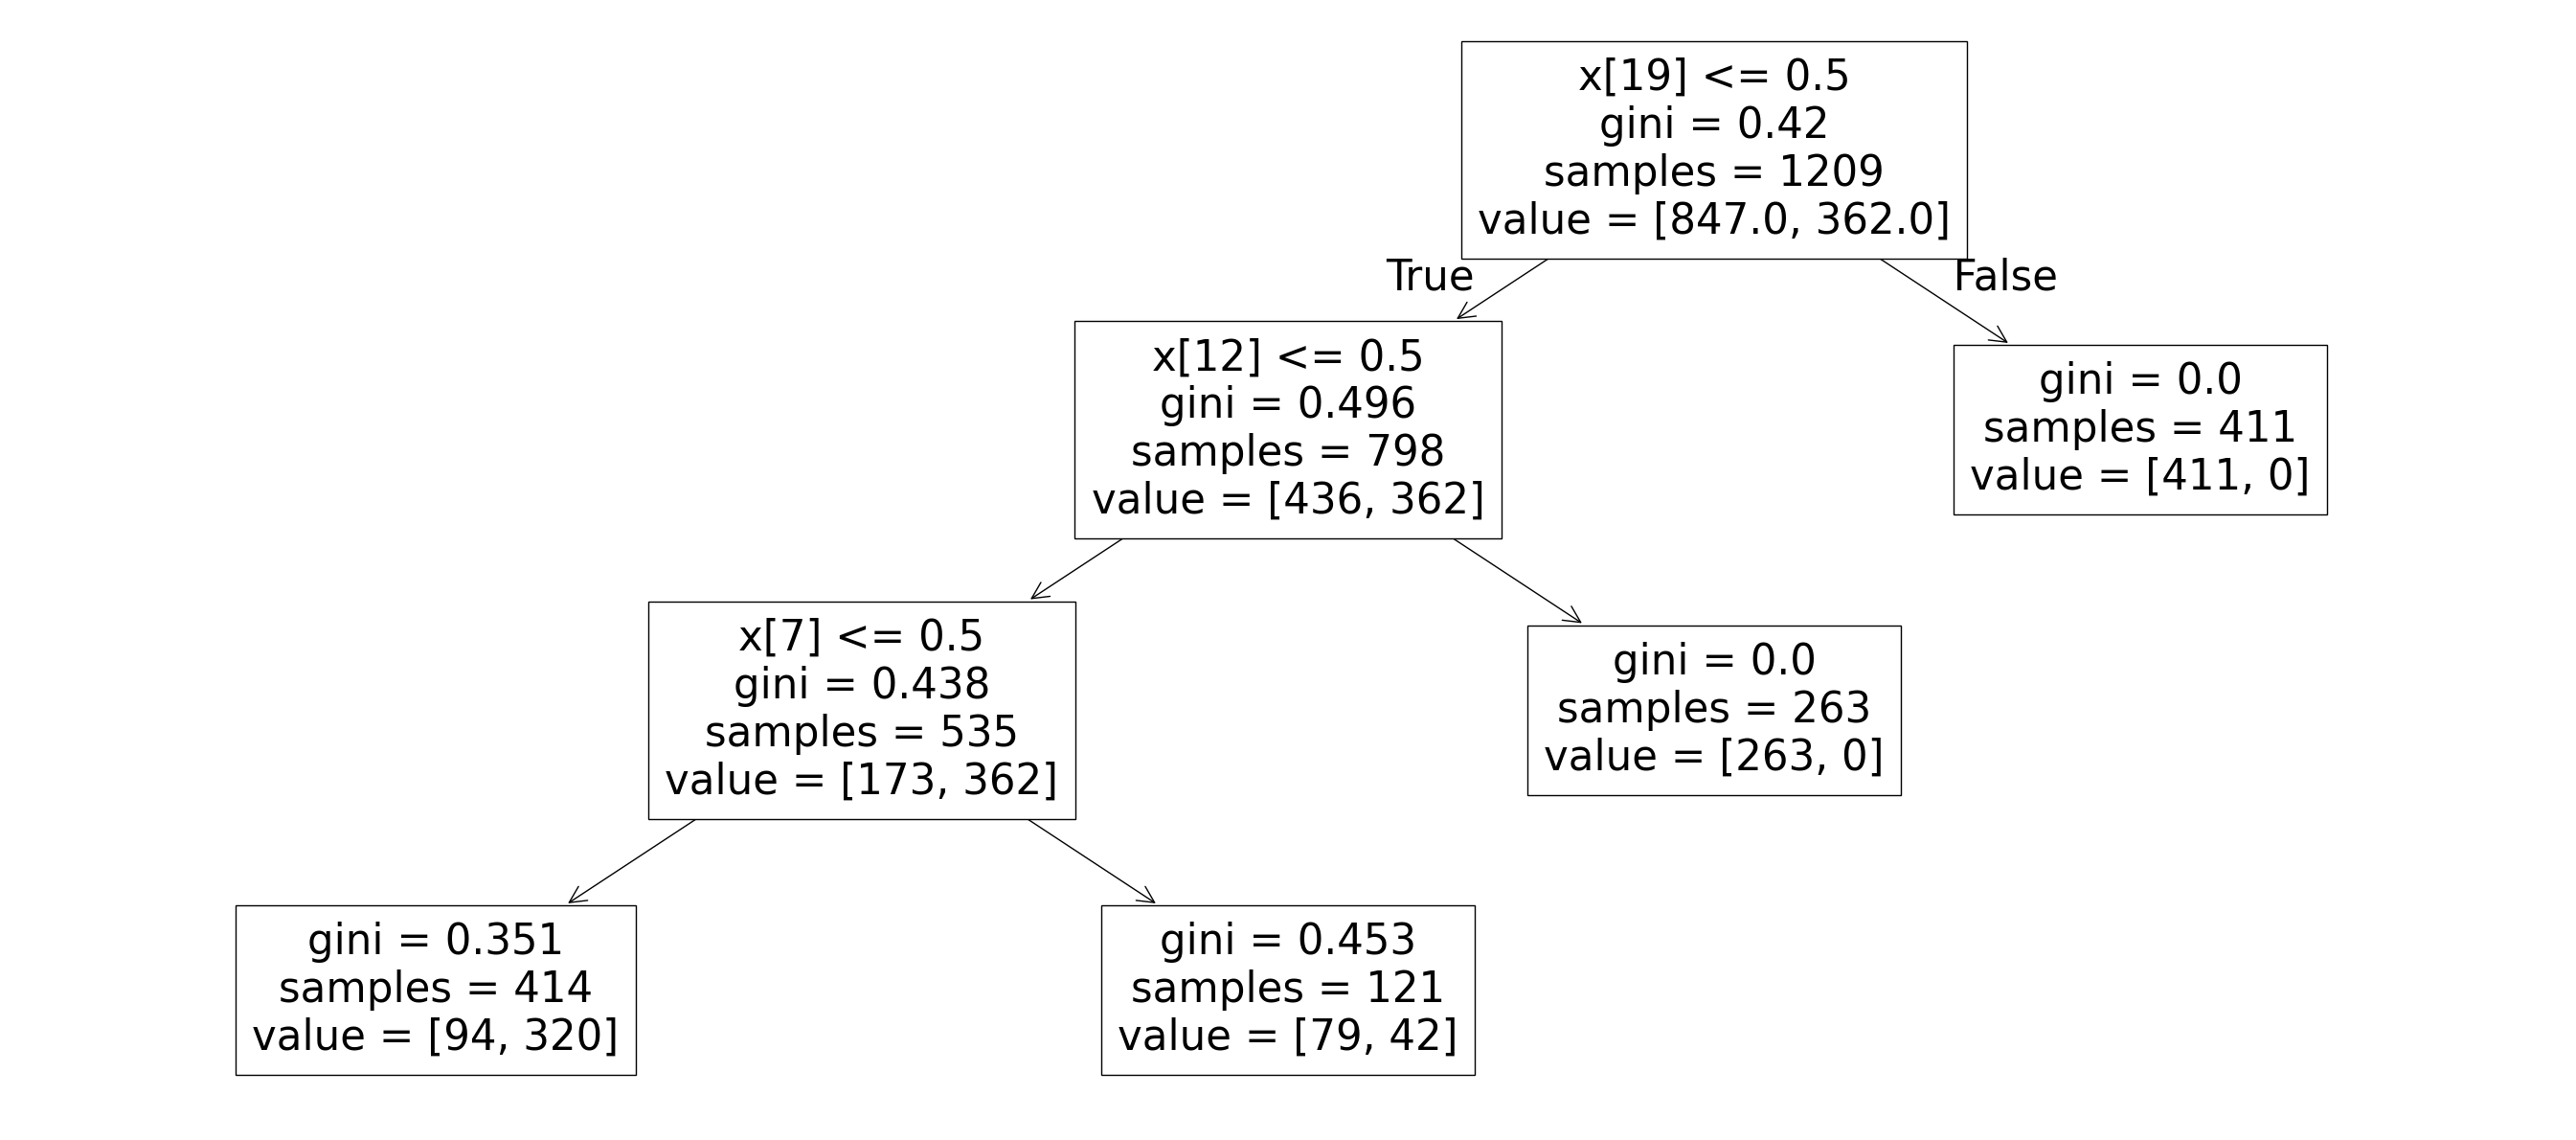

|--- feature_19 <= 0.50
|   |--- feature_12 <= 0.50
|   |   |--- feature_7 <= 0.50
|   |   |   |--- class: True
|   |   |--- feature_7 >  0.50
|   |   |   |--- class: False
|   |--- feature_12 >  0.50
|   |   |--- class: False
|--- feature_19 >  0.50
|   |--- class: False



In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

## Loading the data and setting target and predictor variables
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data', names=['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'accep'])
df['accep'] = ~(df['accep']=='unacc') #1 is acceptable, 0 if not acceptable
X = pd.get_dummies(df.iloc[:,0:6])
y = df['accep']

## Train-test split and fitting the tree
x_train, x_test, y_train, y_test = train_test_split(X,y, random_state=0, test_size=0.3)
dtree = DecisionTreeClassifier(max_depth=3)
dtree.fit(x_train, y_train)

## Visualizing the tree
plt.figure(figsize=(27,12))
tree.plot_tree(dtree)
plt.tight_layout()
plt.show()

## Text-based visualization of the tree (View this in the Output terminal!)
print(tree.export_text(dtree))